# Deep Learning with Python
## A practical course using TensorFlow, Keras and scikit-learn

### Learning objectives
By the end of this notebook, you will be able to:
- Understand machine learning and neural networks.
- Prepare data for regression.
- Explain TensorFlow, Keras and scikit-learn.
- Build and train a neural network.
- Evaluate predictions and identify overfitting.
- Save a trained model and make new predictions.

**Dataset:** `cars.csv`, assumed to contain 42 numeric 'car' features followed by one numeric target 'price' column.

## 1. Install and import the libraries

- **NumPy:** numerical arrays and calculations.
- **pandas:** data loading and inspection.
- **Matplotlib:** visualization.
- **scikit-learn:** preprocessing, data splitting and evaluation.
- **TensorFlow:** numerical computation and automatic differentiation.
- **Keras:** a high-level API for defining and training neural networks.

Run the installation command only if these packages are missing.

In [1]:
%pip install -q tensorflow scikit-learn pandas numpy matplotlib joblib


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: /opt/homebrew/Cellar/jupyterlab/4.1.6_1/libexec/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import joblib

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

tf.keras.utils.set_random_seed(42)

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
NumPy: 2.5.4


## 2. Understand the machine-learning problem

**Regression** predicts a numerical value, such as a price.

- `X`: input features.
- `y`: target value to predict.
- A model learns a relationship between X and y.
- A trained model predicts target values for new inputs.

Neural networks consist of connected neurons with adjustable weights and biases. During training, these parameters are optimized to reduce prediction error.

## 3. Load the dataset

The example dataset is `cars.csv`. A cars dataset typically refers to a collection of data related to various attributes and features of cars. These datasets are often used for machine learning, data analysis, and model building purposes. The code below looks for that file in the notebook's current directory.

If the file is missing, synthetic data can be used to test the complete workflow. Synthetic results are only a programming demonstration, not evidence of real car-price prediction accuracy.

In [3]:
csv_path = "cars.csv"

data = pd.read_csv('cars.csv', header=None)
if os.path.exists(csv_path):
    # Load the CSV
    data = pd.read_csv(csv_path)
    print("Original dataset shape:", data.shape)
    display(data.head())

    # Remove rows with missing values
    data = data.dropna().copy()

    # Separate features (all columns except the last)
    # and target (the last column)
    X = data.iloc[:, :-1].copy()
    y = data.iloc[:, -1].copy()

    # Convert categorical features to numeric columns
    X = pd.get_dummies(X, drop_first=False, dtype=int)

    # Ensure the target is numeric
    y = pd.to_numeric(y, errors="raise")

    # Combine for display
    data = X.copy()
    data["target"] = y.values

    print("Loaded cars.csv successfully.")
    print("Processed dataset shape:", data.shape)

else:
    print("cars.csv not found: using synthetic regression data.")

    X_demo, y_demo = make_regression(
        n_samples=1000,
        n_features=5,
        noise=15,
        random_state=42
    )

    data = pd.DataFrame(X_demo)
    data["target"] = y_demo

display(data.head())
print("Dataset shape:", data.shape)
display(data.describe())

Original dataset shape: (8128, 5)


,brand,km_driven,fuel,owner,selling_price
0,Maruti,145500,Diesel,First Owner,450000
1,Skoda,120000,Diesel,Second Owner,370000
2,Honda,140000,Petrol,Third Owner,158000
3,Hyundai,127000,Diesel,First Owner,225000
4,Maruti,120000,Petrol,First Owner,130000


Loaded cars.csv successfully.
Processed dataset shape: (8128, 43)


,km_driven,brand_Ambassador,brand_Ashok,brand_Audi,brand_BMW,brand_Chevrolet,brand_Daewoo,brand_Datsun,brand_Fiat,brand_Force,...,fuel_CNG,fuel_Diesel,fuel_LPG,fuel_Petrol,owner_First Owner,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner,target
0,145500,0,0,0,0,0,0,0,0,0,...,0,1,0,0,1,0,0,0,0,450000
1,120000,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,1,0,0,370000
2,140000,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,1,158000
3,127000,0,0,0,0,0,0,0,0,0,...,0,1,0,0,1,0,0,0,0,225000
4,120000,0,0,0,0,0,0,0,0,0,...,0,0,0,1,1,0,0,0,0,130000


Dataset shape: (8128, 43)


,km_driven,brand_Ambassador,brand_Ashok,brand_Audi,brand_BMW,brand_Chevrolet,brand_Daewoo,brand_Datsun,brand_Fiat,brand_Force,...,fuel_CNG,fuel_Diesel,fuel_LPG,fuel_Petrol,owner_First Owner,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner,target
count,8.128000e+03,8128.000000,8128.000000,8128.000000,8128.000000,8128.000000,8128.000000,8128.000000,8128.000000,8128.000000,...,8128.000000,8128.000000,8128.000000,8128.000000,8128.000000,8128.000000,8128.000000,8128.000000,8128.000000,8.128000e+03
mean,6.981951e+04,0.000492,0.000123,0.004921,0.014764,0.028297,0.000369,0.007997,0.005782,0.000738,...,0.007013,0.541585,0.004675,0.446727,0.650714,0.021407,0.258981,0.000615,0.068282,6.382718e+05
std,5.655055e+04,0.022180,0.011092,0.069983,0.120613,0.165831,0.019209,0.089073,0.075827,0.027161,...,0.083453,0.498298,0.068220,0.497185,0.476774,0.144747,0.438102,0.024796,0.252246,8.062534e+05
min,1.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.999900e+04
25%,3.500000e+04,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.549990e+05
50%,6.000000e+04,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,4.500000e+05
75%,9.800000e+04,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,6.750000e+05
max,2.360457e+06,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000e+07


## 4. Separate features and target

This example assumes columns 0–42 are features and column 43 is the target - actually the price of a car.

**Important:** verify the column order and units if you use the real car dataset. Never assume the target is the sixth column without checking the source data.

In [4]:
X = data.iloc[:, :-1].to_numpy(dtype=np.float32)
y = data.iloc[:, -1].to_numpy(dtype=np.float32).reshape(-1, 1)

print("Feature matrix:", X.shape)
print("Target matrix:", y.shape)

Feature matrix: (8128, 42)
Target matrix: (8128, 1)


## 5. Split the data before preprocessing

We reserve:
- 64% for training,
- 16% for validation,
- 20% for final testing.

The test set is kept separate until final evaluation. This reduces data leakage and gives a more honest estimate of performance on unseen examples.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42
)

print("Train:", X_train.shape[0])
print("Validation:", X_val.shape[0])
print("Test:", X_test.shape[0])

Train: 5201
Validation: 1301
Test: 1626


## 6. Scale the features and target

Neural networks often train more reliably when inputs have comparable scales.

We use two independent `MinMaxScaler` objects. Each is fitted only on training data. Validation and test data are transformed using the training parameters.

This avoids the common mistake of fitting one scaler to X and then overwriting its parameters by fitting it to y.

In [6]:
x_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()

X_train_s = x_scaler.fit_transform(X_train)
X_val_s = x_scaler.transform(X_val)
X_test_s = x_scaler.transform(X_test)

y_train_s = y_scaler.fit_transform(y_train)
y_val_s = y_scaler.transform(y_val)

print("Scaled feature range:",
      X_train_s.min(), "to", X_train_s.max())

Scaled feature range: 0.0 to 1.0


## 7. Understand the network architecture

The network has three dense layers:

1. **12 neurons:** receives 42 input features.
2. **8 neurons:** learns combinations of the first layer's outputs.
3. **1 neuron:** produces a numerical prediction.

ReLU introduces nonlinearity in the hidden layers. A linear output is suitable for regression because the prediction is not restricted to the interval 0–1.

Each neuron has weights and a bias. With this architecture there are 185 trainable parameters.

In [7]:
model = keras.Sequential([
    keras.Input(shape=(42,)),
    layers.Dense(
        12,
        kernel_initializer="normal",
        activation="relu"
    ),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="linear")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12)             │           516 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 629 (2.46 KB)

 Trainable params: 629 (2.46 KB)

 Non-trainable params: 0 (0.00 B)

## 8. Compile the model

- **MSE:** mean squared error, used as the optimization objective.
- **Adam:** optimizer that updates model parameters using gradients.
- **MAE:** mean absolute error, an additional metric for monitoring performance.

Lower errors are generally better when comparing results on the same target scale.

In [8]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

## 9. Train with validation and early stopping

An epoch is one pass through the training dataset. A batch is a smaller group of samples used for an optimizer update.

Early stopping monitors validation loss. If it stops improving for 15 epochs, training stops and the best observed weights are restored.

In [9]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

history = model.fit(
    X_train_s,
    y_train_s,
    validation_data=(X_val_s, y_val_s),
    epochs=150,
    batch_size=50,
    callbacks=[early_stopping],
    verbose=1
)

print("Epochs completed:", len(history.history["loss"]))

Epoch 1/150
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0045 - mae: 0.0354 - val_loss: 0.0031 - val_mae: 0.0295
Epoch 2/150
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 487us/step - loss: 0.0020 - mae: 0.0248 - val_loss: 0.0021 - val_mae: 0.0253
Epoch 3/150
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 479us/step - loss: 0.0015 - mae: 0.0225 - val_loss: 0.0020 - val_mae: 0.0246
Epoch 4/150
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 471us/step - loss: 0.0014 - mae: 0.0218 - val_loss: 0.0019 - val_mae: 0.0241
Epoch 5/150
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 472us/step - loss: 0.0013 - mae: 0.0214 - val_loss: 0.0018 - val_mae: 0.0234
Epoch 6/150
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 470us/step - loss: 0.0013 - mae: 0.0211 - val_loss: 0.0018 - val_mae: 0.0234
Epoch 7/150
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 467us/step - loss: 0.0013 - mae: 0.0209 - val_loss: 0.0018 - val_mae: 0.0229
Epoch 8/150
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 468us/step - loss: 0.0012 - mae: 0.0208 - val_loss: 0.0017 - val_mae: 0.0228
Epoch 9/150
105/105 ━━━━━━━━━━━━━━

## 10. Visualize learning curves

Training loss measures performance on training samples. Validation loss measures performance on samples not used for weight updates.

If training loss decreases while validation loss rises, the model may be overfitting.

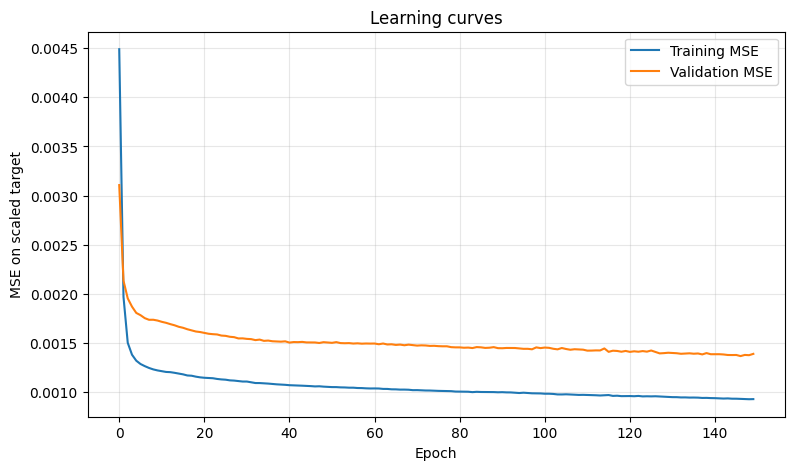

In [10]:
plt.figure(figsize=(9, 5))
plt.plot(history.history["loss"], label="Training MSE")
plt.plot(history.history["val_loss"], label="Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE on scaled target")
plt.title("Learning curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 11. Evaluate the model on the test set

Predictions are converted back to the original target units before calculating metrics.

- **MAE:** average absolute error.
- **MSE:** average squared error.
- **RMSE:** square root of MSE.
- **R²:** predictive performance relative to predicting the mean target. It can be negative on test data.

The target's actual units must be verified before interpreting these errors as a currency amount.

In [11]:
pred_scaled = model.predict(X_test_s, verbose=0)

y_pred = y_scaler.inverse_transform(pred_scaled).ravel()
y_true = y_test.ravel()

mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_true, y_pred)

print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

MAE:  199557.7812
MSE:  119782637568.0000
RMSE: 346096.2837
R²:   0.8173


## 12. Plot actual versus predicted values

The dashed diagonal represents perfect predictions. Points closer to the diagonal indicate smaller prediction errors.

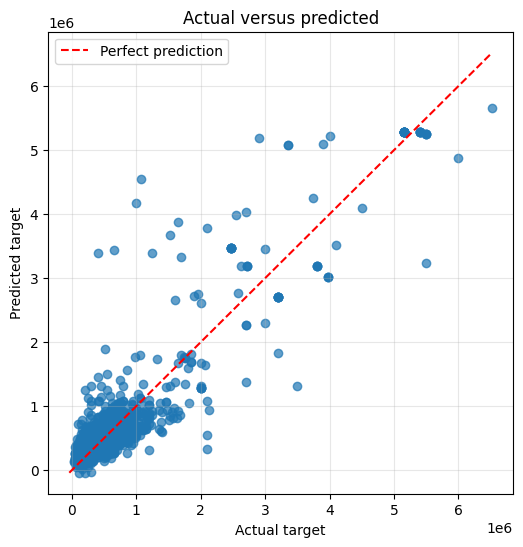

In [12]:
low = min(y_true.min(), y_pred.min())
high = max(y_true.max(), y_pred.max())

plt.figure(figsize=(6, 6))
plt.scatter(y_true, y_pred, alpha=0.7)
plt.plot([low, high], [low, high], "r--", label="Perfect prediction")
plt.xlabel("Actual target")
plt.ylabel("Predicted target")
plt.title("Actual versus predicted")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 13. Compare against simple baselines

A neural network should not be assumed to be the best model. Compare it with:
- a DummyRegressor that predicts the training mean,
- a linear regression model.

The comparison uses the same test samples and the same original target units.

In [13]:
baseline_mean = DummyRegressor(strategy="mean")
baseline_mean.fit(X_train, y_train.ravel())
mean_pred = baseline_mean.predict(X_test)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train.ravel())
linear_pred = linear_model.predict(X_test)

def report(name, actual, predicted):
    print(
        f"{name:20s} "
        f"MAE={mean_absolute_error(actual, predicted):.4f}  "
        f"RMSE={np.sqrt(mean_squared_error(actual, predicted)):.4f}  "
        f"R²={r2_score(actual, predicted):.4f}"
    )

report("Mean baseline", y_true, mean_pred)
report("Linear regression", y_true, linear_pred)
report("Neural network", y_true, y_pred)

Mean baseline        MAE=425468.4688  RMSE=809624.0313  R²=-0.0000
Linear regression    MAE=253645.1875  RMSE=508244.8534  R²=0.6059
Neural network       MAE=199557.7812  RMSE=346096.2837  R²=0.8173


## 14. Predict a new sample

Replace the example values with 42 real feature values in exactly the same order and units as the training data.

The values below are placeholders; they are not verified car specifications.

In [14]:
print("X_train shape:", X_train.shape)
print("X_train type:", type(X_train))
print("Scaler expects:", x_scaler.n_features_in_)
print("Model input shape:", model.input_shape)

print(data.drop("target", axis=1).columns.tolist())

X_train shape: (5201, 42)
X_train type: <class 'numpy.ndarray'>
Scaler expects: 42
Model input shape: (None, 42)
['km_driven', 'brand_Ambassador', 'brand_Ashok', 'brand_Audi', 'brand_BMW', 'brand_Chevrolet', 'brand_Daewoo', 'brand_Datsun', 'brand_Fiat', 'brand_Force', 'brand_Ford', 'brand_Honda', 'brand_Hyundai', 'brand_Isuzu', 'brand_Jaguar', 'brand_Jeep', 'brand_Kia', 'brand_Land', 'brand_Lexus', 'brand_MG', 'brand_Mahindra', 'brand_Maruti', 'brand_Mercedes-Benz', 'brand_Mitsubishi', 'brand_Nissan', 'brand_Opel', 'brand_Peugeot', 'brand_Renault', 'brand_Skoda', 'brand_Tata', 'brand_Toyota', 'brand_Volkswagen', 'brand_Volvo', 'fuel_CNG', 'fuel_Diesel', 'fuel_LPG', 'fuel_Petrol', 'owner_First Owner', 'owner_Fourth & Above Owner', 'owner_Second Owner', 'owner_Test Drive Car', 'owner_Third Owner']


In [15]:
new_sample = X_train[2,:]
new_sample = new_sample.reshape(1, -1)
new_sample_scaled = x_scaler.transform(new_sample)
new_prediction_scaled = model.predict(
    new_sample_scaled, verbose=0
)

new_prediction = y_scaler.inverse_transform(
    new_prediction_scaled
)[0, 0]

print("Predicted target:", new_prediction)

Predicted target: 3.1945825e+06


## 15. Save the model and preprocessing objects

Saving the scalers matters: future input must be transformed using the same parameters learned from training data.

Only load model and pickle/joblib files from sources you trust.

In [16]:
model.save("car_price_model.keras")
joblib.dump(x_scaler, "x_scaler.joblib")
joblib.dump(y_scaler, "y_scaler.joblib")

print("Model and scalers saved.")

Model and scalers saved.


## 16. How the libraries work together

| Tool | Main role |
|---|---|
| NumPy | Numerical arrays |
| pandas | Tabular data loading and inspection |
| scikit-learn | Splitting, scaling, baselines and evaluation |
| Keras | High-level neural network architecture and training API |
| TensorFlow | Tensor operations, automatic differentiation and computation |
| Matplotlib | Plots and diagnostics |

**Workflow:** inspect data → split → preprocess → build → compile → train → validate → test → predict.

Keras defines the network, TensorFlow executes its computations, and scikit-learn provides complementary tools for data preparation and model evaluation.

## 17. Exercises

1. Change the hidden-layer sizes from 12 and 8 to 32 and 16. Compare test MAE.
2. Change the batch size from 50 to 16. Observe training time and learning curves.
3. Change the learning rate to 0.0005. Does validation loss improve?
4. Remove the hidden layers and compare the neural network with linear regression.
5. Explain why the test set should not be used to choose the best epoch.
6. Explain why fitting a scaler before splitting the data can cause data leakage.

### Final lesson

A neural network is only one component of a reliable machine-learning experiment. Data quality, correct preprocessing, validation, independent testing, sensible baselines, and clear interpretation are equally important.